# Long straddle

A long straddle buys a call and a put with the same strike and expiry.
Here we use strike 100, annual volatility 20%, zero interest and no dividends.
Compare 180, 90, 30 and 7 days remaining, holding volatility fixed.
Values are per underlying unit, before subtracting the premium paid.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from straddles import Call, Put

strike = 100
volatility = 0.20
rate = 0.0
expiry_days = [180, 90, 30, 7]
initial_days = max(expiry_days)
spot = np.linspace(60, 140, 801)
colors = ["#440154", "#31688e", "#35b779", "#e69f00"]

straddle = Call(strike, initial_days / 365, volatility) + Put(
    strike, initial_days / 365, volatility
)

# The portfolio takes elapsed time, so convert from days remaining.
elapsed_times = [(initial_days - days) / 365 for days in expiry_days]


def style_axis(ax, title, ylabel):
    ax.set(title=title, xlabel="Underlying price", ylabel=ylabel)
    ax.axvline(strike, color="grey", linestyle=":", linewidth=1)
    ax.set_facecolor("#f2f2f2")
    ax.grid(color="white")
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.legend(title="Time to expiry")

## Theoretical value

As expiry approaches, time value falls and the curve approaches the V-shaped
expiry payoff, $|S-K|$. This is the portfolio's value, not its profit.

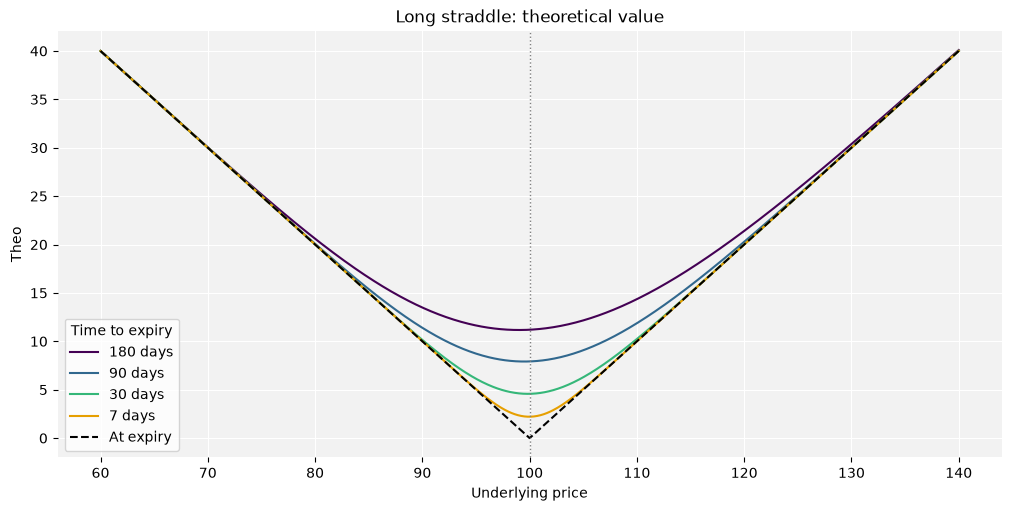

In [2]:
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
for days, elapsed, color in zip(expiry_days, elapsed_times, colors):
    ax.plot(
        spot,
        straddle.theo(spot, elapsed=elapsed, rate=rate),
        color=color,
        label=f"{days} days",
    )
ax.plot(
    spot,
    straddle.theo(spot, elapsed=initial_days / 365, rate=rate),
    color="black",
    linestyle="--",
    label="At expiry",
)
style_axis(ax, "Long straddle: theoretical value", "Theo")
plt.show()

## Delta and gamma

Delta moves from roughly -1 below the strike to +1 above it. Near expiry,
that transition becomes sharper. At the strike, delta is close to zero but
is not exactly zero before expiry under these assumptions.

Gamma is positive for both legs. As expiry approaches, it becomes taller and
more concentrated around the strike. We plot only positive times to expiry
because gamma is undefined at the strike at expiry.

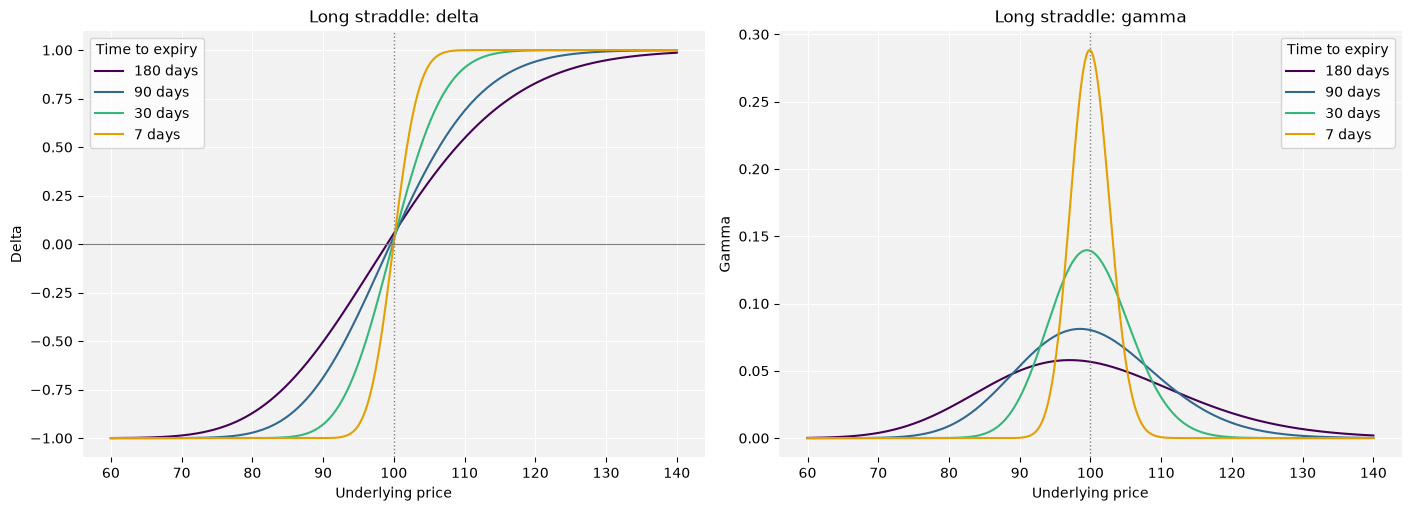

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, layout="constrained")
for days, elapsed, color in zip(expiry_days, elapsed_times, colors):
    axes[0].plot(
        spot,
        straddle.delta(spot, elapsed=elapsed, rate=rate),
        color=color,
        label=f"{days} days",
    )
    axes[1].plot(
        spot,
        straddle.gamma(spot, elapsed=elapsed, rate=rate),
        color=color,
        label=f"{days} days",
    )
axes[0].axhline(0, color="grey", linewidth=0.8)
style_axis(axes[0], "Long straddle: delta", "Delta")
style_axis(axes[1], "Long straddle: gamma", "Gamma")
plt.show()

## Vega

Vega measures sensitivity to implied volatility. Here it is divided by 100,
so the vertical axis shows the value change for a one percentage-point rise
in volatility (for example, 20% to 21%). The long straddle has positive vega,
which falls toward zero as expiry approaches. The position is more valuable if
the volatility has opportunity to realise, so increased volatility increases the position's value but the effect is diminished close to expiry.

- Deep ITM: the payoff is approximately linear over the likely expiry prices. More dispersion adds upside and downside that roughly cancel, so volatility has little effect on value.
- Deep OTM: most likely expiry prices still give zero payoff. A small volatility increase adds little probability or payoff beyond the strike.
- Near the strike: more dispersion creates larger positive payoffs on one side, while the option’s payoff stays floored at zero on the other. That asymmetry makes additional volatility particularly valuable.

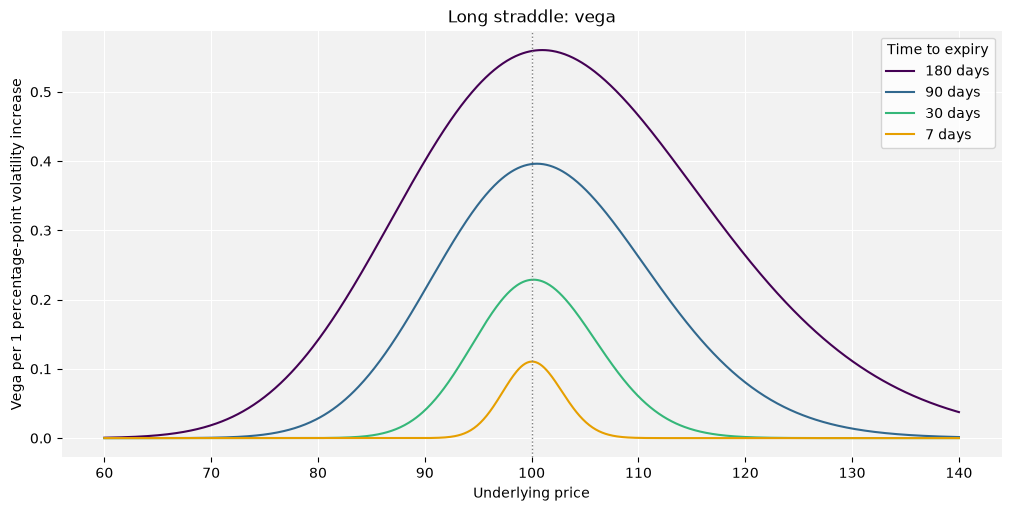

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
for days, elapsed, color in zip(expiry_days, elapsed_times, colors):
    ax.plot(
        spot,
        straddle.vega(spot, elapsed=elapsed, rate=rate) / 100,
        color=color,
        label=f"{days} days",
    )
style_axis(ax, "Long straddle: vega", "Vega per 1 percentage-point volatility increase")
plt.show()